# DT2470 Tempo Estimation
## Jupyter Notebook for development and visualisation purposes

In [1]:
import matplotlib.pyplot as plt
from scipy import signal
import soundfile as sf
import numpy as np

params = {'legend.fontsize': 'x-large','figure.figsize': (15, 6),
         'axes.labelsize': 'x-large','axes.titlesize':'x-large',
         'xtick.labelsize':'x-large','ytick.labelsize':'x-large'}
plt.rcParams.update(params)

<class 'numpy.ndarray'>
44100
(1401848,)
31.787936507936507


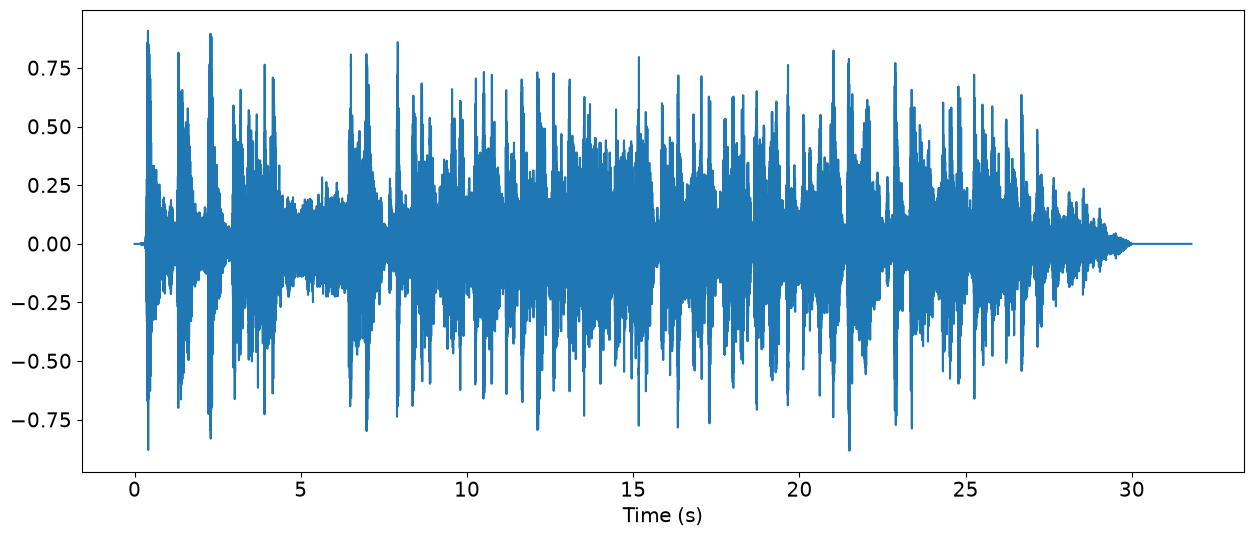

In [ ]:
# using a arbitrarily chosen soundfile without vocals for dev purposes
data, sampleRate = sf.read('data/ballroom/B_1.0/audio/Tango/Albums-Ballroom_Classics4-10.wav')
print(type(data))
print(sampleRate)
print(data.shape)

timeLength = data.size/sampleRate
print(timeLength)
timeAxis = np.linspace(0, timeLength, data.size)
plt.plot(timeAxis, data); plt.xlabel("Time (s)")
plt.show()

### Onset Detection
Using spectral based novelty, according to the following steps:
1. STFT
2. Log-compression
3. Differentiation
4. Accumulation along frequencies
5. Normalize by subtracting moving average

#### STFT

In [3]:
windowLen = int(50/1000 * sampleRate)
windowOverlap = int(25/1000 * sampleRate)
freq, time, Z = signal.stft(data, sampleRate, nperseg=windowLen, noverlap=windowOverlap)
magnitude = np.abs(Z)
# eps = 1e-6 
# ZdB = 20 * (np.log10(np.maximum(magnitude, eps)) - np.log10(np.max(magnitude))) 

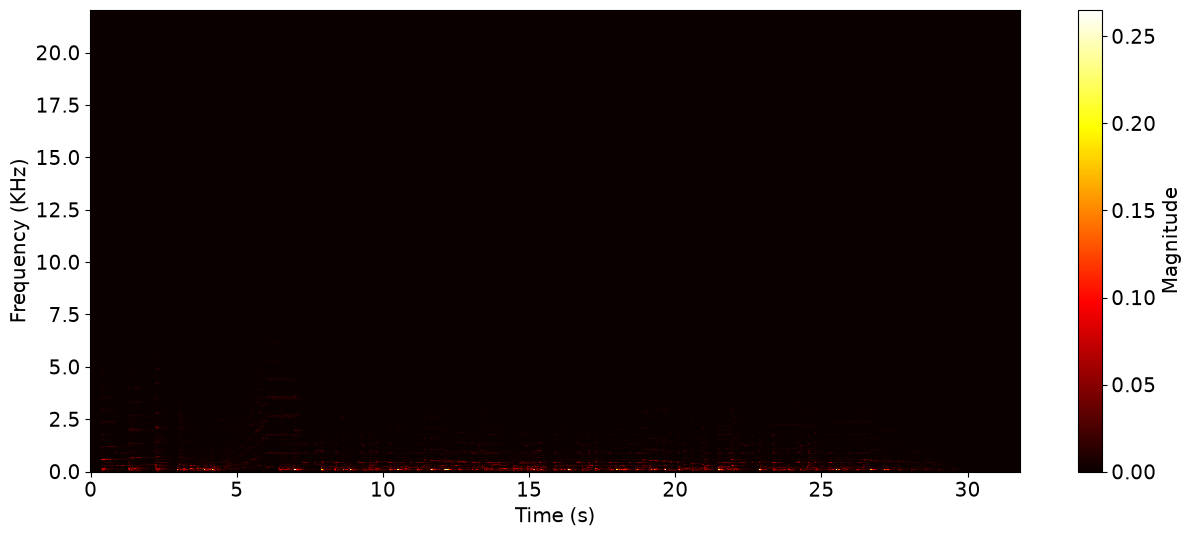

In [10]:
plt.pcolormesh(time, freq/1000, magnitude, cmap='hot')
plt.xlabel("Time (s)"); plt.ylabel("Frequency (KHz)")
plt.colorbar(label="Magnitude")
plt.show()

#### Log-Compression

In [ ]:
# Eq. (6.5)
GAMMA = 1000
magCompressed = np.log(1 + GAMMA * magnitude)

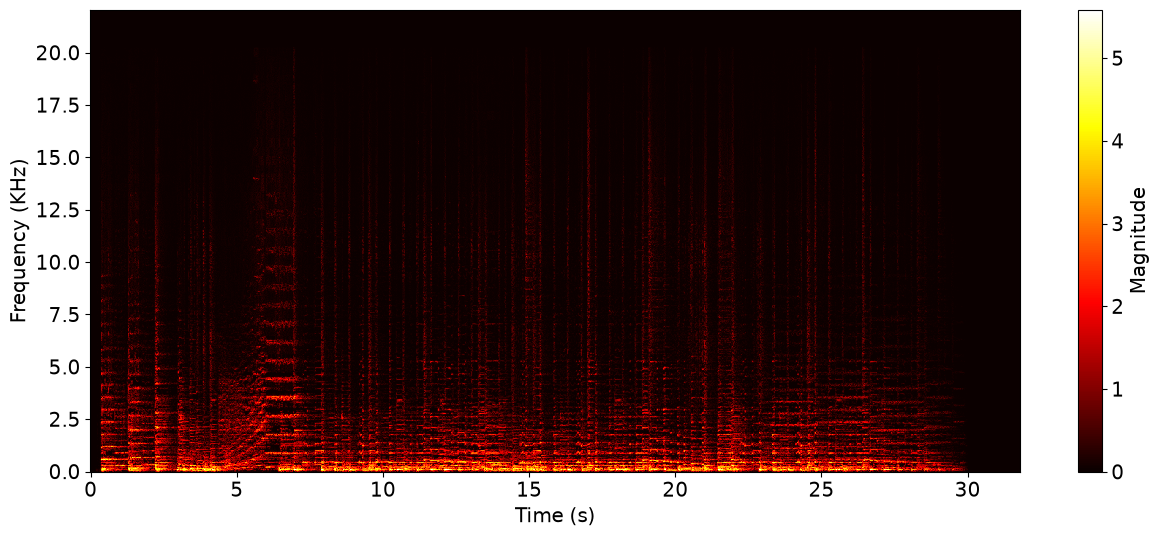

In [9]:
plt.pcolormesh(time, freq/1000, magCompressed, cmap='hot')
plt.xlabel("Time (s)"); plt.ylabel("Frequency (KHz)")
plt.colorbar(label="Magnitude")
plt.show()

#### Differentiation

In [ ]:
# Eq. (6.6)
print(magCompressed.shape)

diff = np.diff(magCompressed, n=1, axis=1)
diff[diff<0] = 0

(1103, 1272)


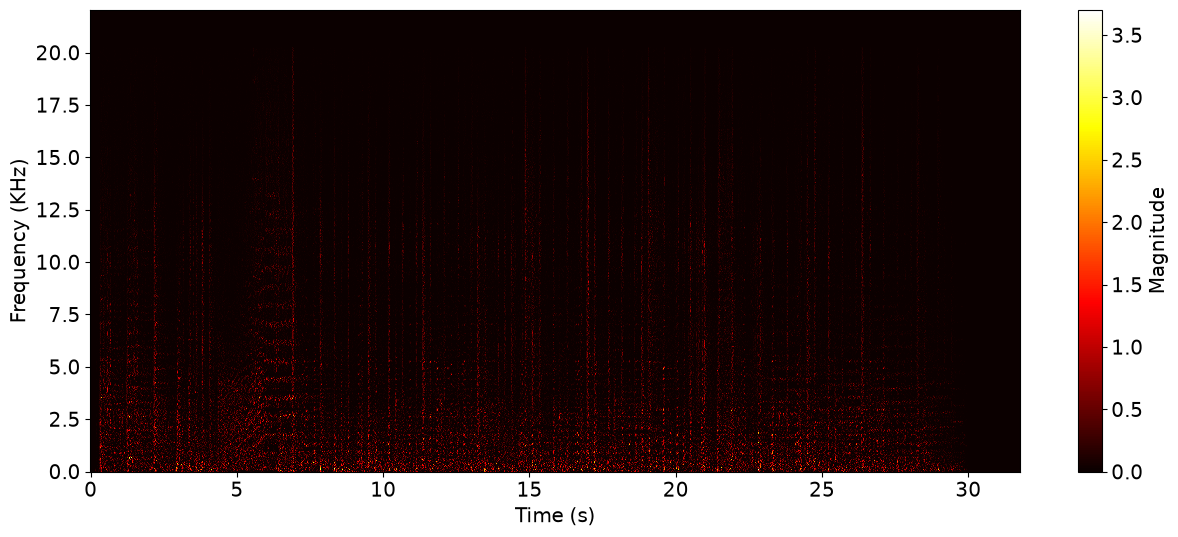

In [11]:
plt.pcolormesh(time[:-1], freq/1000, diff, cmap='hot')
plt.xlabel("Time (s)"); plt.ylabel("Frequency (KHz)")
plt.colorbar(label="Magnitude")
plt.show()

#### Accumulation

In [16]:
# also Eq. (6.6), just the summation over frequencies
novelty = np.sum(diff, axis=0)
FsNovelty = sampleRate / (windowLen - windowOverlap)
print(novelty.shape)

(1271,)


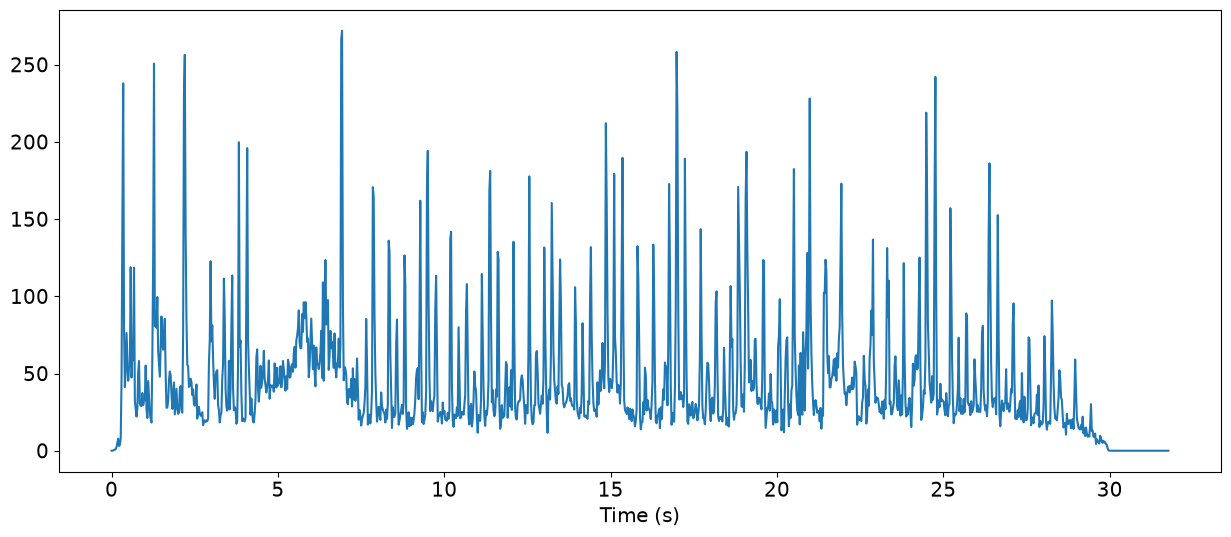

In [ ]:
plt.plot(time[:-1], novelty); 
plt.xlabel("Time (s)"); plt.show()

#### Normalization

In [17]:
# Eq. (6.7) & (6.8)
def compute_local_average(x, M):
    """Compute local average of signal

    Notebook: C6/C6S1_NoveltySpectral.ipynb

    Args:
        x (np.ndarray): Signal
        M (int): Determines size (2M+1) in samples of centric window  used for local average

    Returns:
        local_average (np.ndarray): Local average signal
    """
    L = len(x)
    local_average = np.zeros(L)
    for m in range(L):
        a = max(m - M, 0)
        b = min(m + M + 1, L)
        local_average[m] = (1 / (2 * M + 1)) * np.sum(x[a:b])
    return local_average

MSec = 0.1
M = int(np.ceil(MSec * FsNovelty))

localAverage = compute_local_average(novelty, M)
novNormalised = novelty - localAverage
novNormalised[novNormalised < 0] = 0
novNormalised /= max(novNormalised)

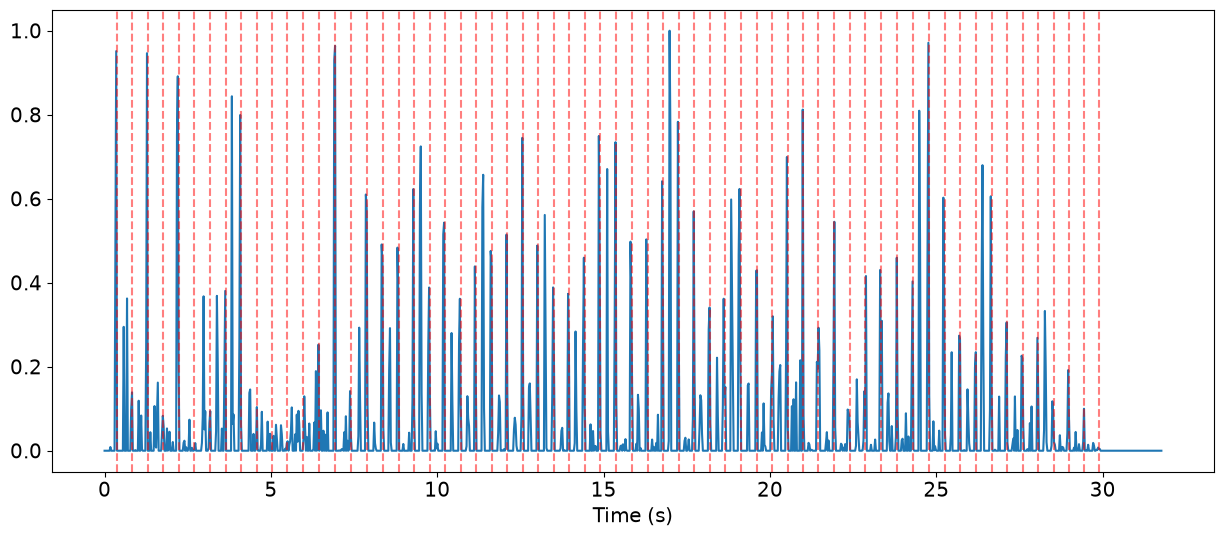

In [ ]:
timeNov = np.arange(novelty.shape[0]) / FsNovelty
plt.plot(timeNov, novNormalised); 
plt.xlabel("Time (s)")

with open('data/ballroom/B_1.0/annotations/beats/Albums-Ballroom_Classics4-10.beats') as f:
    for beat in f:
        beat = beat.split()[0]
        plt.axvline(float(beat), color='r', linestyle='--', alpha=0.5)

plt.show()

### Tempograms
